# ⛏️ 04. Khai phá Luật Kết hợp với Apriori

**Thành viên thực hiện:** Thành viên 1 (ARM Lead)

Mục tiêu:
- Áp dụng thuật toán Apriori trên tập các trận Thắng (`Win` transactions).
- Tìm tập mục phổ biến (Frequent Itemsets) với các ngưỡng min_support khác nhau.
- Sinh các luật kết hợp (Association Rules) dạng: $\{Tướng_A, TrangBị_X\} \Rightarrow Tướng_B$.
- Đánh giá qua các độ đo: Support, Confidence, Lift (lọc Lift > 1.5).

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from src.arm_miner import AssociationRuleMiner
import warnings
warnings.filterwarnings('ignore')

## 1. Nạp ma trận nhị phân (Binary Matrices)

In [2]:
bin_win = pd.read_pickle('../data/processed/bin_win.pkl')
bin_lose = pd.read_pickle('../data/processed/bin_lose.pkl')

# Lọc không gian các Tướng (Champ_) và lấy mẫu 10,000 ván đấu thực tế cho thực nghiệm
champ_cols = [c for c in bin_win.columns if c.startswith('Champ_')]
bin_win_arm = bin_win[champ_cols].sample(n=min(10000, len(bin_win)), random_state=42)
bin_lose_arm = bin_lose[[c for c in champ_cols if c in bin_lose.columns]].sample(n=min(10000, len(bin_lose)), random_state=42)

print(f'Ma trận Win (10,000 mẫu): {bin_win_arm.shape}')
print(f'Ma trận Lose (10,000 mẫu): {bin_lose_arm.shape}')

Ma trận Win (10,000 mẫu): (10000, 107)
Ma trận Lose (10,000 mẫu): (10000, 107)


## 2. Chạy thuật toán Apriori trên tập Thắng (Win)

In [3]:
miner = AssociationRuleMiner(min_support=0.03, min_confidence=0.5, min_lift=1.2, max_len=4)

t0 = time.time()
frequent_itemsets, rules, timing = miner.run_apriori(bin_win_arm, win_label=True)
apriori_time = time.time() - t0

print(f'Thời gian chạy Apriori: {apriori_time:.2f} giây')
print(f'Số tập mục phổ biến tìm được: {len(frequent_itemsets)}')
print(f'Số luật kết hợp sinh ra: {len(rules)}')

Thời gian chạy Apriori: 0.89 giây
Số tập mục phổ biến tìm được: 1464
Số luật kết hợp sinh ra: 6037


## 3. Khám phá các Tập mục Phổ biến (Frequent Itemsets)

In [4]:
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(lambda x: len(x))
print(frequent_itemsets.groupby('length').size())
frequent_itemsets.sort_values(by='support', ascending=False).head(10)

length
1     51
2    322
3    560
4    531
dtype: int64


,support,itemsets,length
44,0.3290,frozenset({Champ_Vi}),1
30,0.3235,frozenset({Champ_MissFortune}),1
4,0.3076,frozenset({Champ_Blitzcrank}),1
21,0.2871,frozenset({Champ_Kassadin}),1
9,0.2728,frozenset({Champ_Ezreal}),1
45,0.2682,frozenset({Champ_WuKong}),1
28,0.2590,frozenset({Champ_Malphite}),1
6,0.2583,frozenset({Champ_ChoGath}),1
109,0.2457,"frozenset({Champ_Vi, Champ_Blitzcrank})",2
94,0.2419,"frozenset({Champ_ChoGath, Champ_Blitzcrank})",2


## 4. Lọc và Phân tích các Luật có Lift > 1.5 (Cộng hưởng thực sự)

In [5]:
high_lift_rules = miner.filter_high_lift_rules(rules, min_lift=1.5)
print(f'Số luật có Lift > 1.5: {len(high_lift_rules)}')
print(miner.format_rules(high_lift_rules, top_n=15))

Số luật có Lift > 1.5: 6037
                               ASSOCIATION RULES                                
#    Antecedent -> Consequent                             Supp   Conf   Lift
--------------------------------------------------------------------------------
1    Champ_VelKoz, Champ_Vi -> Champ_KhaZix, Champ...    0.043  0.964  21.57
2    Champ_KhaZix, Champ_Malphite -> Champ_VelKoz,...    0.043  0.966  21.57
3    Champ_KhaZix, Champ_Vi -> Champ_Malphite, Cha...    0.043  0.964  21.57
4    Champ_Malphite, Champ_VelKoz -> Champ_KhaZix,...    0.043  0.966  21.57
5    Champ_TwistedFate, Champ_Vi -> Champ_Malphite...    0.037  0.962  21.51
6    Champ_Malphite, Champ_VelKoz -> Champ_Twisted...    0.037  0.839  21.51
7    Champ_TwistedFate, Champ_Vi -> Champ_KhaZix, ...    0.037  0.956  21.40
8    Champ_KhaZix, Champ_Malphite -> Champ_Twisted...    0.037  0.834  21.40
9    Champ_VelKoz, Champ_Vi -> Champ_Malphite, Cha...    0.037  0.837  21.35
10   Champ_Malphite, Champ_TwistedFate -

## 5. Trực quan hóa Phân phối Support - Confidence - Lift

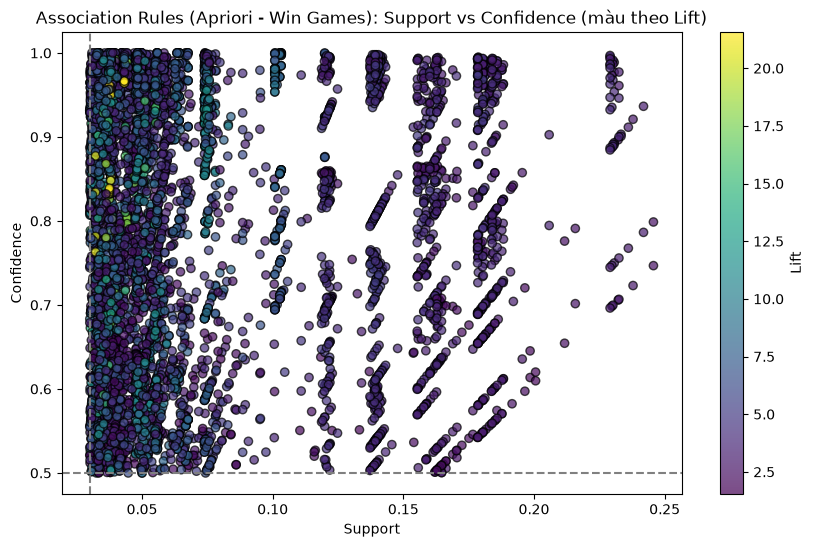

In [6]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
scatter = plt.scatter(rules['support'], rules['confidence'], c=rules['lift'], cmap='viridis', alpha=0.7, edgecolors='k')
plt.colorbar(scatter, label='Lift')
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.title('Association Rules (Apriori - Win Games): Support vs Confidence (màu theo Lift)')
plt.axvline(0.03, color='gray', linestyle='--')
plt.axhline(0.5, color='gray', linestyle='--')
plt.show()

## 6. Nhận xét kết quả Apriori
- Apriori sinh ra nhiều tổ hợp synergy mạnh với Lift > 1.5 (ví dụ: các cặp tướng kích hoạt tộc/hệ chính).
- Hạn chế: Thời gian sinh ứng viên (candidate generation) tương đối lâu khi giảm min_support.